# Master flat

`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 11 Oct 2023

Reference: *Handbook of CCD Astronomy*, §4.5 and __[CCD Data Reduction Guide #Flat fielding](https://www.astropy.org/ccd-reduction-and-photometry-guide/v/dev/notebooks/05-00-Flat-corrections.html)__
* build master flat
* check statistical properties
* propagate uncertainties
* save as FITS file in the `reference` folder

In [1]:
# import and settings
%matplotlib notebook
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
import astropy.io.fits as pf
from astropy.stats import mad_std
from astropy import units as u
from astropy.visualization import ZScaleInterval
import ccdproc as ccdp

## Load previously computed data 

In [2]:
# define CCD characteristics
# ccd_gain = x.xxx * u.electron / u.adu
# ccd_ron = y.yyy * u.electron

In [3]:
# load master bias and print stats
master_bias = ccdp.CCDData.read('reference/master_bias.fits', unit='adu')
npix = master_bias.shape[0]*master_bias.shape[1]
print('npix    mean    median  std  ')
print('-----------------------------')
print("%7d %5.1f   %5.1f  %5.1f" % (npix, np.mean(master_bias.data), np.median(master_bias.data), np.std(master_bias.data)))

INFO: using the unit adu passed to the FITS reader instead of the unit adu in the FITS file. [astropy.nddata.ccddata]
npix    mean    median  std  
-----------------------------
4194304 299.9   299.9    2.1


In [4]:
# create raw image collection
ifc_raw = ccdp.ImageFileCollection('raw/')

## Collect and check flat field frames

In [5]:
# create flat-field image collection and print summary
ifc_flatH = ifc_raw.filter(imagetyp='Flat Field', filter='Halpha_OHP')
flat_summary = ifc_flatH.summary
print(flat_summary['file', 'date-obs', 'imagetyp', 'object', 'filter', 'exposure'])

        file                date-obs         imagetyp  object   filter   exposure
-------------------- ---------------------- ---------- ------ ---------- --------
raw/flat-0001_H.fits 2020-09-16T04:16:07.13 Flat Field   flat Halpha_OHP     30.0
raw/flat-0002_H.fits 2020-09-16T04:16:43.44 Flat Field   flat Halpha_OHP     30.0
raw/flat-0003_H.fits 2020-09-16T04:17:19.38 Flat Field   flat Halpha_OHP     30.0
                 ...                    ...        ...    ...        ...      ...
raw/flat-0018_H.fits 2020-09-16T04:26:26.75 Flat Field   flat Halpha_OHP     30.0
raw/flat-0019_H.fits 2020-09-16T04:27:02.68 Flat Field   flat Halpha_OHP     30.0
raw/flat-0020_H.fits 2020-09-16T04:27:38.62 Flat Field   flat Halpha_OHP     30.0
Length = 20 rows


In [6]:
### ToDo: print flat statistics and look for outliers/problematic frames

## Compute master flat field

In [7]:
# compute master flat
master_flatH = ccdp.combine(ifc_flatH.files_filtered(include_path=True), unit='adu', combine='average', mem_limit=512.e6)

INFO:astropy:splitting each image into 8 chunks to limit memory usage to 512000000.0 bytes.


INFO: splitting each image into 8 chunks to limit memory usage to 512000000.0 bytes. [ccdproc.combiner]


In [8]:
# set header keyword (will appear in the saved file)
master_flatH.meta['COMBINED'] = True

In [9]:
### ToDo: compare statiscal properties of the flat field series with those of the master frame

<IPython.core.display.Javascript object>


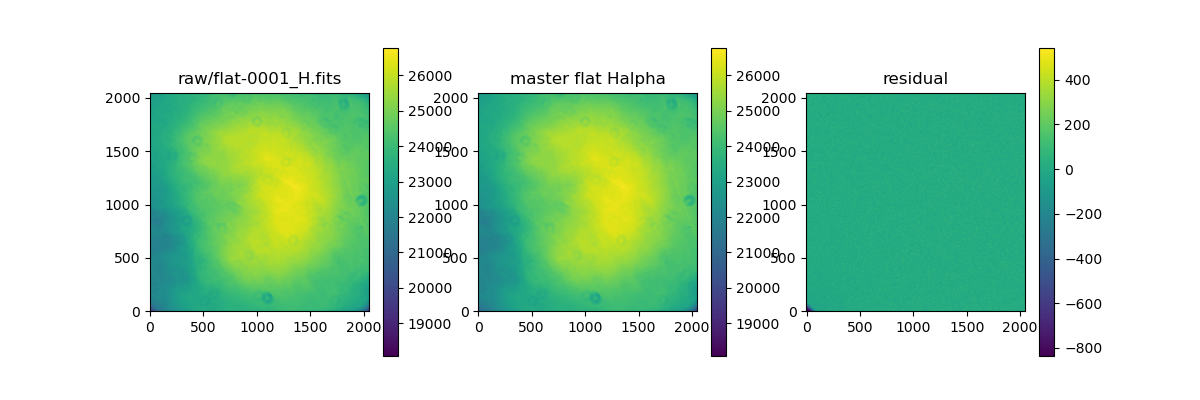

In [10]:
# display 1st flat, master flat and residual
fig = plt.figure(figsize=(12,4))
#
ax1 = fig.add_subplot(131)
ccd_flat1 = ccdp.CCDData.read(ifc_flatH.files[0], unit='adu')
interval1 = ZScaleInterval()
z1, z2 = interval1.get_limits(ccd_flat1)
im1 = ax1.imshow(ccd_flat1.data, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im1)
ax1.set_title(ifc_flatH.files[0])
#
ax2 = fig.add_subplot(132)
im2 = ax2.imshow(master_flatH.data, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im2)
ax2.set_title('master flat Halpha')
#
ax3 = fig.add_subplot(133)
res_flatH = ccd_flat1.data - master_flatH.data
interval2 = ZScaleInterval()
z1, z2 = interval2.get_limits(res_flatH)
im3 = ax3.imshow(res_flatH, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im3)
ax3.set_title('residual')
plt.show()


In [11]:
### ToDo: print statistics of the 3 images above

In [12]:
### ToDo: display histograms for the 3 images above

In [13]:
### Further work: compute expected photon noise in single flat-field frame and compare with
###               mean/median uncertainty on master flat

In [14]:
# print uncertainty in master flat-field frame
print("mean/median uncertainty on master_flatH: %.3e / %.3e" %\
      (np.mean(master_flatH.uncertainty.array), np.median(master_flatH.uncertainty.array)))

mean/median uncertainty on master_flatH: 3.411e+01 / 3.392e+01


## Subtract master bias and normalize the master flat

In [15]:
# bias subtract the master flat field
master_flatH = ccdp.subtract_bias(master_flatH, master_bias)

In [16]:
### ToDo: display histograms for the 3 images above

In [17]:
# normalise the master flat field by its mean value
master_flatH = master_flatH.divide(np.mean(master_flatH.data))
### Important remarks:
###   - the method CCDData.divide ensure that uncertainties are correctly propagated
###   - it is not sctrictly necesssary to normalize the master flat since ccdproc.flat_correct will do it by default
###     (see next notebook)

In [18]:
### ToDo: display statistics and histogram for the normalized flat field

## Save master normalized master flat

In [19]:
# once master flat is fine-tuned save it
#master_flatH.write('reference/master_flatH.fits')
master_flatH.write('reference/master_flatH.fits', overwrite=True)

## Further work

In [ ]:
### Further work: 
### 1. experiment with options of the function ccdproc.combine: 
###    method, scale, sigma_clip
### 2. define keywords gain and readnoise for uncertainty propagation and check the result